# 74 · ACT (Action Chunking with Transformers) from scratch on TableTop

In [1]:
import os, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate, show_video
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import ACT, train_policy, ChunkPolicy

from vlacourse import scene_dataset
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
os.makedirs("checkpoints", exist_ok=True)
H = 16

In [2]:
ds = TableTopDataset(DATA, episodes=range(450), horizon=H)
net = ACT(horizon=H, kl_weight=10.0)
print(f"ACT parameters: {sum(p.numel() for p in net.parameters()) / 1e6:.1f}M  (ResNet-18 backbone {sum(p.numel() for p in net.obs.parameters()) / 1e6:.1f}M)")
if os.path.exists("checkpoints/act.pt"):
    net.load_state_dict(torch.load("checkpoints/act.pt", map_location=device)); net.to(device); losses = None
else:
    t0 = time.time(); losses = train_policy(net, ds, epochs=50, lr=1e-4, device=device, log_every=5)
    torch.save(net.state_dict(), "checkpoints/act.pt"); print(f"trained in {time.time() - t0:.0f}s")
    plt.figure(figsize=(7, 3.5)); plt.semilogy(np.convolve(losses, np.ones(50) / 50, "valid")); plt.xlabel("step"); plt.ylabel("L1 + 10·KL"); plt.show()

vlacourse/chunk_policies.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  enc = lambda: nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 8, 4 * d, 0.1, batch_first=True, norm_first=True), layers)


ACT parameters: 21.9M  (ResNet-18 backbone 11.2M)


ACT, temporal ensembling   success 0.96 CI [0.87, 0.99] per task {'pick': 0.92, 'place': 1.0}


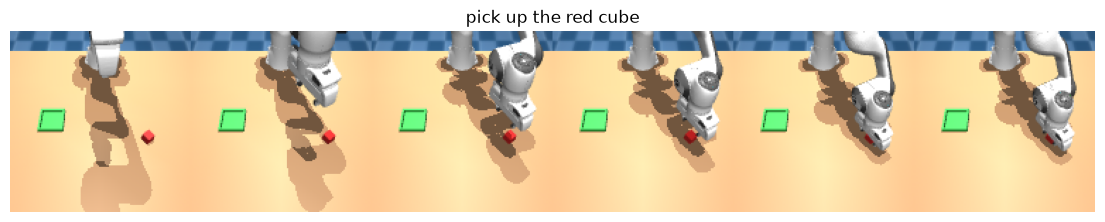

ACT, execute 8 of 16       success 0.96 CI [0.87, 0.99] per task {'pick': 0.92, 'place': 1.0}


In [3]:
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
for name, pol in [("ACT, temporal ensembling", ChunkPolicy(net, ds, env, device, ensemble=True)), ("ACT, execute 8 of 16", ChunkPolicy(net, ds, env, device, execute=8))]:
    r = evaluate(env, pol, n_episodes=50, seed=50_000, record=2 if "ensembling" in name else 0)
    print(f"{name:26s} success {r['success']:.2f} CI [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}] per task {r['per_task']}")
    if r["videos"]:
        show_video([f for v in r["videos"] for f in v], fps=10, title=name)
        plt.figure(figsize=(14, 2.5)); plt.imshow(np.hstack(r["videos"][0][::max(1, len(r['videos'][0]) // 6)][:6])); plt.axis("off"); plt.title(r["episodes"][0]["instruction"]); plt.show()

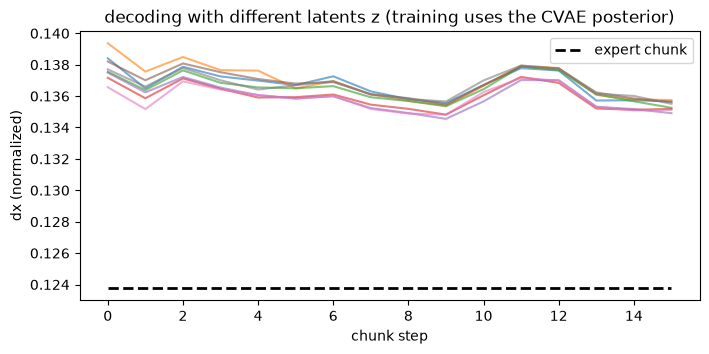

In [4]:
b = {k: v[None].to(device) for k, v in ds[500].items() if k != "pad_mask"}
net.eval()
with torch.no_grad():
    mem = net._memory(b, torch.zeros(1, net.z_dim, device=device), augment=False)
    chunks = [net._decode(net._memory(b, torch.randn(1, net.z_dim, device=device) * 2, augment=False))[0].cpu().numpy() for _ in range(8)]
plt.figure(figsize=(8, 3.5))
for c in chunks:
    plt.plot(c[:, 0], alpha=0.6)
plt.plot(b["action"][0, :, 0].cpu(), "k--", lw=2, label="expert chunk")
plt.xlabel("chunk step"); plt.ylabel("dx (normalized)"); plt.legend(); plt.title("decoding with different latents z (training uses the CVAE posterior)"); plt.show()